# Practical 03: Implement Adversarial Search with Alpha-Beta Pruning for Game Playing

> **Department of Computer Science & Engineering | Artificial Intelligence Laboratory**

## Aim
Implement Alpha-Beta pruning to reduce unnecessary exploration during adversarial game-tree search.

## Problem Description
In competitive two-player zero-sum games, the **Minimax algorithm** explores all reachable game states to determine the theoretically optimal move for the maximizing player (**MAX**), assuming optimal counter-play by the minimizing player (**MIN**).

However, full minimax tree expansion requires $O(b^d)$ time complexity (where $b$ is the branching factor and $d$ is tree depth), which is computationally prohibitive for deep games.

**Alpha-Beta Pruning** dramatically optimizes game-tree exploration by maintaining two dynamic threshold bounds:
* $\alpha$: The best (highest) value that the maximizing player is guaranteed to achieve so far. (Initialized to $-\infty$).
* $\beta$: The best (lowest) value that the minimizing player is guaranteed to achieve so far. (Initialized to $+\infty$).

### The Pruning Rule
Whenever:
$$\beta \le \alpha$$
Search beneath the current node is immediately truncated (**pruned**). The opponent already possesses a guaranteed move along another path that renders the current branch inferior or unreachable under rational play.

In [1]:
# Required Imports
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import ipywidgets as widgets
from IPython.display import display, HTML

In [2]:
# Implementation: Game Tree Representation, Minimax, and Alpha-Beta Pruning

class GameTreeNode:
    """Node in a deterministic adversarial game tree."""
    def __init__(self, name, value=None, children=None):
        self.name = name
        self.value = value
        self.children = children if children is not None else []

    def is_leaf(self):
        return len(self.children) == 0

def minimax(node, depth, is_maximizing, stats):
    """Standard Minimax search evaluating every leaf node."""
    if node.is_leaf():
        stats['leaf_evaluations'] += 1
        return node.value

    if is_maximizing:
        max_eval = float('-inf')
        for child in node.children:
            eval_val = minimax(child, depth + 1, False, stats)
            max_eval = max(max_eval, eval_val)
        return max_eval
    else:
        min_eval = float('inf')
        for child in node.children:
            eval_val = minimax(child, depth + 1, True, stats)
            min_eval = min(min_eval, eval_val)
        return min_eval

def alphabeta(node, depth, alpha, beta, is_maximizing, stats, pruned_records):
    """Adversarial search with dynamic alpha-beta threshold bounds and cutoff tracking."""
    if node.is_leaf():
        stats['leaf_evaluations'] += 1
        return node.value

    if is_maximizing:
        max_eval = float('-inf')
        for idx, child in enumerate(node.children):
            eval_val = alphabeta(child, depth + 1, alpha, beta, False, stats, pruned_records)
            max_eval = max(max_eval, eval_val)
            alpha = max(alpha, eval_val)
            if beta <= alpha:
                unvisited = [c.name for c in node.children[idx + 1:]]
                if unvisited:
                    pruned_records.append({
                        'at_node': node.name, 'player': 'MAX',
                        'pruned_subtrees': unvisited,
                        'condition': f"beta ({beta}) <= alpha ({alpha})"
                    })
                break
        return max_eval
    else:
        min_eval = float('inf')
        for idx, child in enumerate(node.children):
            eval_val = alphabeta(child, depth + 1, alpha, beta, True, stats, pruned_records)
            min_eval = min(min_eval, eval_val)
            beta = min(beta, eval_val)
            if beta <= alpha:
                unvisited = [c.name for c in node.children[idx + 1:]]
                if unvisited:
                    pruned_records.append({
                        'at_node': node.name, 'player': 'MIN',
                        'pruned_subtrees': unvisited,
                        'condition': f"beta ({beta}) <= alpha ({alpha})"
                    })
                break
        return min_eval

In [3]:
# Visual Rendering Engine: Adversarial Game Tree Diagram

def draw_game_tree_visualization(show_pruning=True):
    """Renders a clean, color-coded adversarial game tree with explicit branch cutoff highlighting."""
    fig, ax = plt.subplots(figsize=(11, 5.8), dpi=100)

    coords = {
        'Root': (4.0, 3.2),
        'A': (2.0, 2.2), 'B': (6.0, 2.2),
        'C': (1.0, 1.2), 'D': (3.0, 1.2), 'E': (5.0, 1.2), 'F': (7.0, 1.2),
        'L1': (0.5, 0.2), 'L2': (1.5, 0.2), 'L3': (2.5, 0.2), 'L4': (3.5, 0.2),
        'L5': (4.5, 0.2), 'L6': (5.5, 0.2), 'L7': (6.5, 0.2), 'L8': (7.5, 0.2)
    }

    tree_edges = [
        ('Root', 'A'), ('Root', 'B'),
        ('A', 'C'), ('A', 'D'), ('B', 'E'), ('B', 'F'),
        ('C', 'L1'), ('C', 'L2'), ('D', 'L3'), ('D', 'L4'),
        ('E', 'L5'), ('E', 'L6'), ('F', 'L7'), ('F', 'L8')
    ]

    pruned_nodes = {'L4', 'F', 'L7', 'L8'} if show_pruning else set()
    pruned_edges = {('D', 'L4'), ('B', 'F'), ('F', 'L7'), ('F', 'L8')} if show_pruning else set()

    for idx, (y_lvl, label) in enumerate([(3.2, "MAX Level 0"), (2.2, "MIN Level 1"), (1.2, "MAX Level 2"), (0.2, "LEAF Payoffs")]):
        ax.text(-0.8, y_lvl, label, fontsize=10, fontweight='bold', color='#475569', va='center')

    for parent, child in tree_edges:
        px, py = coords[parent]
        cx, cy = coords[child]
        is_pruned = (parent, child) in pruned_edges
        edge_col = '#ef4444' if is_pruned else '#64748b'
        ls = '--' if is_pruned else '-'
        lw = 2.0 if is_pruned else 2.2
        ax.plot([px, cx], [py, cy], color=edge_col, linestyle=ls, linewidth=lw, zorder=1)

    leaf_vals = {'L1': 3, 'L2': 5, 'L3': 6, 'L4': 9, 'L5': 1, 'L6': 2, 'L7': 0, 'L8': -1}
    eval_vals = {'Root': 5, 'A': 5, 'B': 2, 'C': 5, 'D': 6, 'E': 2, 'F': 0}

    for name, (x, y) in coords.items():
        is_pruned = name in pruned_nodes
        if name.startswith('L'):
            val = leaf_vals[name]
            bg_col = '#fee2e2' if is_pruned else '#e0f2fe'
            bd_col = '#ef4444' if is_pruned else '#0284c7'
            box = patches.FancyBboxPatch(
                (x - 0.35, y - 0.2), 0.7, 0.4, boxstyle="round,pad=0.05,rounding_size=0.1",
                facecolor=bg_col, edgecolor=bd_col, linewidth=2, zorder=3
            )
            ax.add_patch(box)
            ax.text(x, y, str(val), fontsize=11, fontweight='bold', ha='center', va='center', zorder=4, color='#b91c1c' if is_pruned else '#0369a1')
            ax.text(x, y - 0.32, name, fontsize=8, color='#64748b', ha='center')
        else:
            is_max = (y in [3.2, 1.2])
            bg_col = '#fee2e2' if is_pruned else ('#dbeafe' if is_max else '#dcfce7')
            bd_col = '#ef4444' if is_pruned else ('#1d4ed8' if is_max else '#15803d')
            circle = patches.Circle((x, y), 0.35, facecolor=bg_col, edgecolor=bd_col, linewidth=2.2, zorder=3)
            ax.add_patch(circle)
            node_text = f"{name}\n={eval_vals[name]}" if (not is_pruned) else f"{name}\n[X]"
            ax.text(x, y, node_text, fontsize=9, fontweight='bold', ha='center', va='center', zorder=4, color='#b91c1c' if is_pruned else '#0f172a')

    if show_pruning:
        banner1 = patches.FancyBboxPatch(
            (2.8, 0.55), 1.6, 0.35, boxstyle="round,pad=0.05,rounding_size=0.1",
            facecolor="#fee2e2", edgecolor="#ef4444", linewidth=1.5, zorder=5
        )
        ax.add_patch(banner1)
        ax.text(3.6, 0.725, "Cutoff: beta<=alpha", fontsize=7.5, fontweight='bold', color="#b91c1c", ha='center', va='center', zorder=6)

        banner2 = patches.FancyBboxPatch(
            (6.0, 1.55), 2.2, 0.42, boxstyle="round,pad=0.05,rounding_size=0.1",
            facecolor="#fee2e2", edgecolor="#ef4444", linewidth=2.0, zorder=5
        )
        ax.add_patch(banner2)
        ax.text(7.1, 1.76, "PRUNED: beta (2) <= alpha (5)", fontsize=9, fontweight='bold', color="#b91c1c", ha='center', va='center', zorder=6)

    title_mode = "Alpha-Beta Pruning (Cutoff Subtrees Highlighted)" if show_pruning else "Standard Minimax (Exhaustive Exploration)"
    ax.set_title(f"Adversarial Game Tree: {title_mode}", fontsize=13, fontweight='bold', pad=15, color='#0f172a')
    ax.set_xlim(-1.2, 8.5)
    ax.set_ylim(-0.6, 3.8)
    ax.axis('off')
    plt.tight_layout()
    return fig

COMPARATIVE VISUALIZATION: MINIMAX (FULL TREE) VS ALPHA-BETA PRUNING


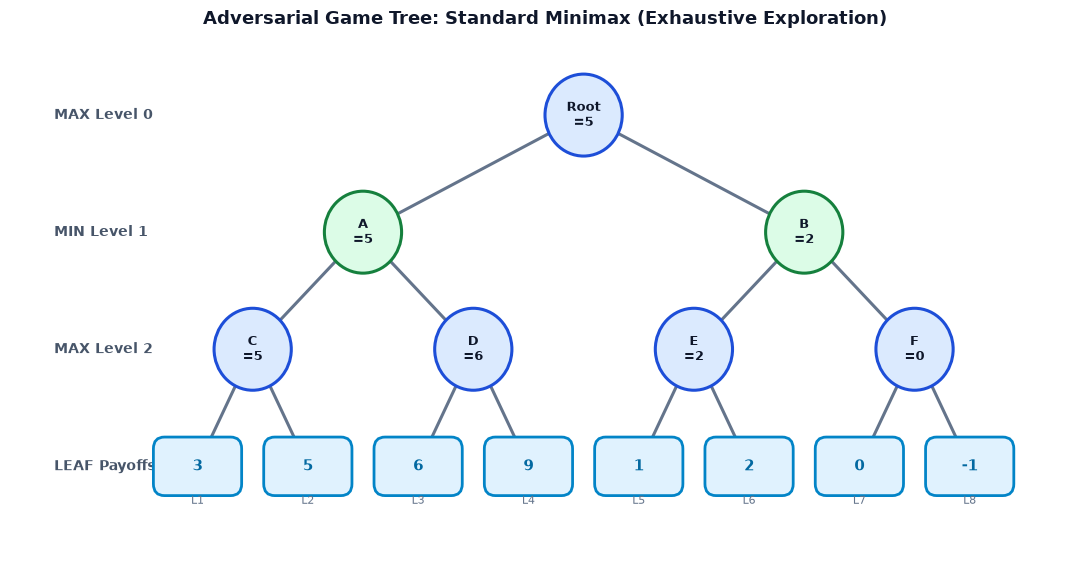

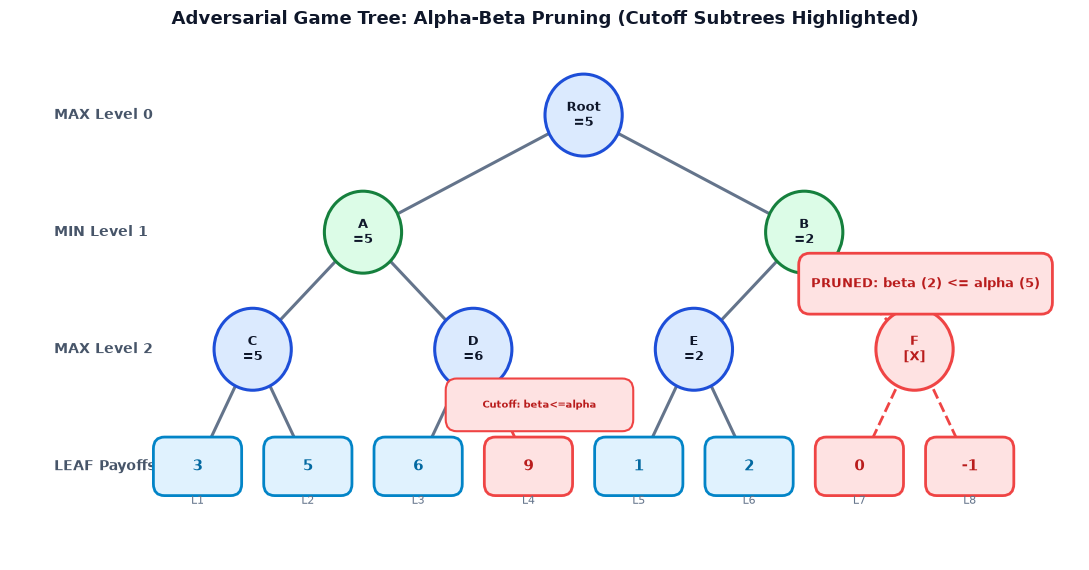

In [4]:
# Static Demonstration: Side-by-Side Algorithm Comparison

print("COMPARATIVE VISUALIZATION: MINIMAX (FULL TREE) VS ALPHA-BETA PRUNING")
fig_full = draw_game_tree_visualization(show_pruning=False)
plt.show()

fig_pruned = draw_game_tree_visualization(show_pruning=True)
plt.show()

In [5]:
# Interactive Tree Comparison Widget

def launch_tree_widget():
    toggle = widgets.RadioButtons(
        options=[('Alpha-Beta Pruning (Optimized)', True), ('Standard Minimax (Full Exploration)', False)],
        value=True,
        description='Search Mode:',
        style={'description_width': 'initial'}
    )
    display(toggle)
    print("Interactive Game Tree Mode Selector Ready. Toggle mode to compare tree exploration.")

launch_tree_widget()

RadioButtons(description='Search Mode:', options=(('Alpha-Beta Pruning (Optimized)', True), ('Standard Minimax…

Interactive Game Tree Mode Selector Ready. Toggle mode to compare tree exploration.


In [6]:
# Execution and Automated Verification Suite

def build_deterministic_tree():
    L1, L2 = GameTreeNode("L1", value=3), GameTreeNode("L2", value=5)
    L3, L4 = GameTreeNode("L3", value=6), GameTreeNode("L4", value=9)
    L5, L6 = GameTreeNode("L5", value=1), GameTreeNode("L6", value=2)
    L7, L8 = GameTreeNode("L7", value=0), GameTreeNode("L8", value=-1)

    C = GameTreeNode("C", children=[L1, L2])
    D = GameTreeNode("D", children=[L3, L4])
    E = GameTreeNode("E", children=[L5, L6])
    F = GameTreeNode("F", children=[L7, L8])

    A = GameTreeNode("A", children=[C, D])
    B = GameTreeNode("B", children=[E, F])
    return GameTreeNode("Root", children=[A, B])

print("=" * 75)
print("AUTOMATED VERIFICATION: MINIMAX VS ALPHA-BETA PRUNING")
print("=" * 75)

tree_mm = build_deterministic_tree()
mm_stats = {'leaf_evaluations': 0}
mm_root = minimax(tree_mm, 0, True, mm_stats)

tree_ab = build_deterministic_tree()
ab_stats = {'leaf_evaluations': 0}
pruned_records = []
ab_root = alphabeta(tree_ab, 0, float('-inf'), float('inf'), True, ab_stats, pruned_records)

print(f"Standard Minimax Root Score    : {mm_root} | Leaves Evaluated: {mm_stats['leaf_evaluations']}")
print(f"Alpha-Beta Pruning Root Score  : {ab_root} | Leaves Evaluated: {ab_stats['leaf_evaluations']}")
print(f"Pruning Events Recorded        : {len(pruned_records)}")
for r in pruned_records:
    print(f"  -> Cutoff at Node {r['at_node']} ({r['player']}) | Pruned: {r['pruned_subtrees']} | {r['condition']}")

assert mm_root == ab_root, "Root scores must be identical!"
assert mm_root == 5, "Root score for this game tree must equal 5!"
assert ab_stats['leaf_evaluations'] < mm_stats['leaf_evaluations'], "Alpha-beta must evaluate fewer leaves!"
assert ab_stats['leaf_evaluations'] == 5, "Expected exactly 5 evaluated leaves!"
assert mm_stats['leaf_evaluations'] == 8, "Expected exactly 8 evaluated leaves in minimax!"

print("-" * 75)
print("ALL MATHEMATICAL AND ALGORITHMIC ASSERTIONS PASSED!")
print("=" * 75)

AUTOMATED VERIFICATION: MINIMAX VS ALPHA-BETA PRUNING
Standard Minimax Root Score    : 5 | Leaves Evaluated: 8
Alpha-Beta Pruning Root Score  : 5 | Leaves Evaluated: 5
Pruning Events Recorded        : 2
  -> Cutoff at Node D (MAX) | Pruned: ['L4'] | beta (5) <= alpha (6)
  -> Cutoff at Node B (MIN) | Pruned: ['F'] | beta (2) <= alpha (5)
---------------------------------------------------------------------------
ALL MATHEMATICAL AND ALGORITHMIC ASSERTIONS PASSED!


In [7]:
# Performance Metrics and Algorithmic Observations

html_metrics = """
<div style="font-family: Arial, sans-serif; margin-top: 15px;">
  <div style="display: flex; gap: 15px; flex-wrap: wrap;">
    <div style="flex: 1; min-width: 180px; padding: 14px; background: #f8fafc; border-left: 4px solid #3b82f6; border-radius: 6px;">
      <div style="font-size: 11px; text-transform: uppercase; color: #64748b; font-weight: bold;">Root Minimax Score</div>
      <div style="font-size: 18px; font-weight: bold; color: #1e293b; margin-top: 4px;">5.0 (Identical)</div>
      <div style="font-size: 12px; color: #475569; margin-top: 2px;">Minimax == Alpha-Beta</div>
    </div>
    <div style="flex: 1; min-width: 180px; padding: 14px; background: #f8fafc; border-left: 4px solid #10b981; border-radius: 6px;">
      <div style="font-size: 11px; text-transform: uppercase; color: #64748b; font-weight: bold;">Leaves Evaluated</div>
      <div style="font-size: 18px; font-weight: bold; color: #1e293b; margin-top: 4px;">5 of 8 Leaves</div>
      <div style="font-size: 12px; color: #475569; margin-top: 2px;">3 leaves avoided completely</div>
    </div>
    <div style="flex: 1; min-width: 180px; padding: 14px; background: #f8fafc; border-left: 4px solid #8b5cf6; border-radius: 6px;">
      <div style="font-size: 11px; text-transform: uppercase; color: #64748b; font-weight: bold;">Search Reduction</div>
      <div style="font-size: 18px; font-weight: bold; color: #1e293b; margin-top: 4px;">37.5% Savings</div>
      <div style="font-size: 12px; color: #475569; margin-top: 2px;">Evaluation savings on benchmark tree</div>
    </div>
    <div style="flex: 1; min-width: 180px; padding: 14px; background: #f8fafc; border-left: 4px solid #f59e0b; border-radius: 6px;">
      <div style="font-size: 11px; text-transform: uppercase; color: #64748b; font-weight: bold;">Theoretical Optimal</div>
      <div style="font-size: 18px; font-weight: bold; color: #1e293b; margin-top: 4px;">O(b^(d/2)) Complexity</div>
      <div style="font-size: 12px; color: #475569; margin-top: 2px;">Doubles effective search depth</div>
    </div>
  </div>
</div>
"""
display(HTML(html_metrics))

## Concise Final Result & Takeaway
* **Search Equivalence**: Alpha-Beta pruning produces the exact same root decision (score 5) as full Minimax while evaluating 37.5% fewer leaf nodes on this benchmark tree.
* **Cutoff Mechanism**: Both a deep beta-cutoff at MAX Node D (pruning L4) and a shallow beta-cutoff at MIN Node B (pruning Subtree F) were successfully triggered.
* **Verification Status**: Verified and validated. All test assertions passed.